In [2]:
import transformers
import torch
import datasets
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, DataCollatorForSeq2Seq
import matplotlib.pyplot as plt
from vllm import LLM, SamplingParams
import copy

INFO 06-09 23:09:29 [__init__.py:243] Automatically detected platform cuda.


### Basic Execution Environment Information

In [3]:
print("Transformers version:", transformers.__version__)
print("Torch version:", torch.__version__)
print("Datasets version:", datasets.__version__)
print("VLLM version:", transformers.__version__)

Transformers version: 4.52.3
Torch version: 2.7.0+cu126
Datasets version: 3.6.0
VLLM version: 4.52.3


In [4]:
print("Number of CUDA devices:", torch.cuda.device_count())
print("Current CUDA device:", torch.cuda.current_device())

Number of CUDA devices: 8
Current CUDA device: 0


### Download the Dataset
In this experiment, we use the [DeepMath-103K](https://huggingface.co/datasets/zwhe99/DeepMath-103K) mathematical reasoning training set. DeepMath-103K is a challenging math dataset containing 103K samples, each annotated with a difficulty level and three reasoning paths from DeepSeek-R1. In addition, a key feature of DeepMath-103K is that it has been deduplicated against existing major math test sets, ensuring that the training set does not contain samples from mainstream math benchmarks.

In [ ]:
# Use the datasets API to load the dataset
data = load_dataset("zwhe99/DeepMath-103K")

In [32]:
data

DatasetDict({
    train: Dataset({
        features: ['question', 'final_answer', 'difficulty', 'topic', 'r1_solution_1', 'r1_solution_2', 'r1_solution_3'],
        num_rows: 103022
    })
})

### Tokenizer and chat_template
The Tokenizer converts natural language text in string form into model-acceptable input (a list of integer IDs). chat_template is specific to large models and defines how to organize requests into a conversation format.

In [ ]:
# Load the Tokenizer
qwen_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-Math-1.5B")
print(qwen_tokenizer.chat_template)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'Please reason step by step, and put your final answer within \\boxed{}.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nPlease reason step by step, and

In [ ]:
# The apply_chat_template method converts a conversation history into an input format with special tokens
# Here tokenize=False means no tokenization is performed, and add_generation_prompt=False means no generation prompt is added
# The generated example shows how the actual user input is organized
text = "hello world"
print(qwen_tokenizer.apply_chat_template([{"role": "user", "content": text}, {"role": "assistant", "content": "hi!"}], tokenize=False, add_generation_prompt=False))

<|im_start|>system
Please reason step by step, and put your final answer within \boxed{}.<|im_end|>
<|im_start|>user
hello world<|im_end|>
<|im_start|>assistant
hi!<|im_end|>



### Dataset Preprocessing
We mainly perform the following two preprocessing steps on the data:
1. Filter the data to keep only questions whose answer is a pure number
2. Filter by length to keep only questions with length less than 4096

In [ ]:
# Data filtering: keep only samples whose answer is a pure number
data_with_number_answer = data["train"].filter(
    lambda x: x["final_answer"].isdigit()
)
print(len(data_with_number_answer))

In [ ]:
# Data preprocessing: use the first DeepSeek-R1 output for each question as the reference answer, and convert it into a format containing length (for later filtering), input_ids, and labels (for training)
def tokenize(example):
    question = example["question"]
    r1_solution = example["r1_solution_1"]
    message = [{"role": "user", "content": question}, {"role": "assistant", "content": f"<think>\n{r1_solution}\n"}]
    result = qwen_tokenizer.apply_chat_template(message, add_generation_prompt=False, tokenize=True, return_dict=True)
    result["length"] = len(result["input_ids"])
    result["labels"] = result["input_ids"].copy()
    return result

train = data_with_number_answer.map(tokenize, batched=False, num_proc=16)

In [ ]:
# Data example: R1's response contains advanced reasoning characteristics such as self-reflection, thought switching, and verification
# This is a sample actually fed into the model for training
print(qwen_tokenizer.decode(train[0]["input_ids"], skip_special_tokens=False))

<|im_start|>system
Please reason step by step, and put your final answer within \boxed{}.<|im_end|>
<|im_start|>user
Evaluate the limit: \[ \lim_{x \to \infty} \sqrt{x} \left( \sqrt[3]{x+1} - \sqrt[3]{x-1} \right) \]<|im_end|>
<|im_start|>assistant
<think>
Okay, so I have this limit to evaluate: the limit as x approaches infinity of the square root of x times the difference between the cube root of (x plus 1) and the cube root of (x minus 1). Hmm, let me write that down again to make sure I have it right.

\[
\lim_{x \to \infty} \sqrt{x} \left( \sqrt[3]{x+1} - \sqrt[3]{x-1} \right)
\]

Alright, so it's the product of sqrt(x) and the difference of two cube roots. Since x is going to infinity, both x+1 and x-1 are going to be very close to x when x is large. But their cube roots might differ by a small amount, and multiplying by sqrt(x) could amplify that difference. The question is whether this product approaches a finite limit, zero, or infinity.

I remember that when dealing with limi

#### Length Filtering
For training convenience, we use the maximum length of Qwen/Qwen2.5-Math-1.5B, 4096, as the cutoff and keep only samples shorter than the model's maximum length

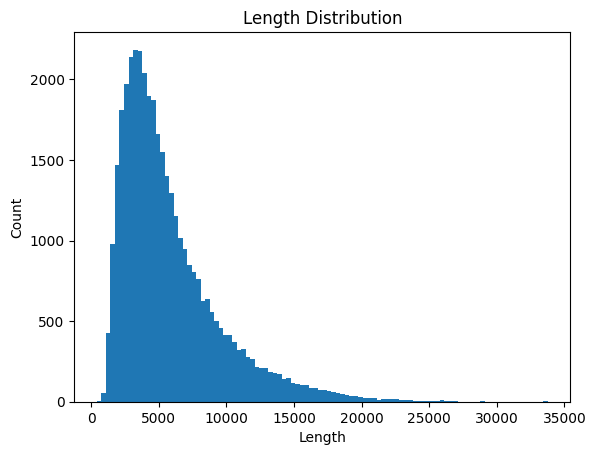

In [ ]:
# Length distribution visualization: the mean length of R1's responses is about 5000
lengths = train["length"]
plt.hist(lengths, bins=100)
plt.xlabel("Length")
plt.ylabel("Count")
plt.title("Length Distribution")
plt.show()

In [ ]:
# Data filtering: keep only samples with length less than 4096
train = train.filter(lambda x: x["length"] < 4096, num_proc=16)
print(len(train))

15310


### Train the Model
For convenience, we use Qwen/Qwen2.5-Math-1.5B as the base model for the experiment. Qwen/Qwen2.5-Math-1.5B is a base model that has not undergone instruction tuning, so it cannot produce normal instruction-following outputs and can only perform ordinary in-context learning (ICL) generation. We will load this model and fine-tune it in BF16 precision. The experiment uses a single A100 GPU with 80GB of memory.

In [ ]:
# Load the model
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-Math-1.5B", torch_dtype=torch.bfloat16, device_map="auto")
model

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotary_emb): Qw

In [ ]:
# Set the training parameters
training_args = TrainingArguments(
    # batch size & epochs
    per_device_train_batch_size=4, # If you run out of GPU memory, set this to 1
    gradient_accumulation_steps=16,
    num_train_epochs=3,
    # hyperparameters
    learning_rate=1e-6,
    lr_scheduler_type="cosine",
    # monitoring
    output_dir="./checkpoints",
    logging_dir="./checkpoints/logs",
    report_to="tensorboard",
    eval_strategy="no",
    save_strategy="steps",
    save_steps=100,
    save_total_limit=1,
    # efficiency
    bf16=True,
    group_by_length=True,
    torch_compile=True,
    gradient_checkpointing=False, # If you run out of GPU memory, set this to True
    # reproducibility
    seed=42,
    data_seed=42
)

# Set the default DataCollator for seq2seq tasks
collator = DataCollatorForSeq2Seq(
    qwen_tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt",
)

In [ ]:
# Train using Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train,
    processing_class=qwen_tokenizer,
    data_collator=collator,
)
trainer.train()

In [ ]:
# After training, save the final model
trainer.save_model("./checkpoints/final_model")

### Testing
After training the model, we need to test the performance of the trained model. We use the widely used MATH500 test set. MATH500 is a subset of the [MATH](https://datasets-benchmarks-proceedings.neurips.cc/paper_files/paper/2021/file/be83ab3ecd0db773eb2dc1b0a17836a1-Paper-round2.pdf) test set, containing 500 high-school competition-level math problems. Each problem is annotated with its corresponding difficulty.

In [ ]:
# Load the data
math500 = load_dataset("zwhe99/MATH", split="math500")

In [ ]:
# Inspect the data format
math500[0]

{'problem': 'Convert the point $(0,3)$ in rectangular coordinates to polar coordinates.  Enter your answer in the form $(r,\\theta),$ where $r > 0$ and $0 \\le \\theta < 2 \\pi.$',
 'level': 'Level 2',
 'type': 'Precalculus',
 'solution': 'We have that $r = \\sqrt{0^2 + 3^2} = 3.$  Also, if we draw the line connecting the origin and $(0,3),$ this line makes an angle of $\\frac{\\pi}{2}$ with the positive $x$-axis.\n\n[asy]\nunitsize(0.8 cm);\n\ndraw((-0.5,0)--(3.5,0));\ndraw((0,-0.5)--(0,3.5));\ndraw(arc((0,0),3,0,90),red,Arrow(6));\n\ndot((0,3), red);\nlabel("$(0,3)$", (0,3), W);\ndot((3,0), red);\n[/asy]\n\nTherefore, the polar coordinates are $\\boxed{\\left( 3, \\frac{\\pi}{2} \\right)}.$',
 'id': 'test/precalculus/807.json',
 'expected_answer': '(3,\\frac{\\pi}{2})'}

In [ ]:
## Preprocessing: format the questions into a conversation format suitable for model input 
data = []
for line in math500:
    line = copy.deepcopy(line)
    line["messages"] = [{"role": "user", "content": line["problem"]}]
    data.append(line)
print(len(data))

500


#### Model Generation
We use vLLM as our inference backend. Set the `base_model` path to the path of the model you actually want to test.

In [ ]:
base_model = "./checkpoints/final_model"
llm = LLM(
    model=base_model,
    tensor_parallel_size=1,
    max_model_len=4096
)
tokenizer = AutoTokenizer.from_pretrained(base_model)

INFO 06-09 10:29:30 [__init__.py:31] Available plugins for group vllm.general_plugins:
INFO 06-09 10:29:30 [__init__.py:33] - lora_filesystem_resolver -> vllm.plugins.lora_resolvers.filesystem_resolver:register_filesystem_resolver
INFO 06-09 10:29:30 [__init__.py:36] All plugins in this group will be loaded. Set `VLLM_PLUGINS` to control which plugins to load.


INFO 06-09 10:29:37 [config.py:793] This model supports multiple tasks: {'score', 'embed', 'classify', 'reward', 'generate'}. Defaulting to 'generate'.
INFO 06-09 10:29:37 [config.py:2118] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 06-09 10:29:38 [utils.py:2531] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reason: CUDA is initialized
INFO 06-09 10:29:41 [__init__.py:243] Automatically detected platform cuda.
INFO 06-09 10:29:43 [core.py:438] Waiting for init message from front-end.
INFO 06-09 10:29:43 [__init__.py:31] Available plugins for group vllm.general_plugins:
INFO 06-09 10:29:43 [__init__.py:33] - lora_filesystem_resolver -> vllm.plugins.lora_resolvers.filesystem_resolver:register_filesystem_resolver
INFO 06-09 10:29:43 [__init__.py:36] All plugins in this group will be loaded. Set `VLLM

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.43it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.43it/s]



INFO 06-09 10:29:45 [default_loader.py:280] Loading weights took 0.35 seconds
INFO 06-09 10:29:45 [gpu_model_runner.py:1549] Model loading took 2.8798 GiB and 0.501736 seconds
INFO 06-09 10:29:50 [backends.py:459] Using cache directory: /data4/home/chenxy/.cache/vllm/torch_compile_cache/18e2887e28/rank_0_0 for vLLM's torch.compile
INFO 06-09 10:29:50 [backends.py:469] Dynamo bytecode transform time: 5.23 s
INFO 06-09 10:29:54 [backends.py:132] Directly load the compiled graph(s) for shape None from the cache, took 3.585 s
INFO 06-09 10:29:55 [monitor.py:33] torch.compile takes 5.23 s in total
INFO 06-09 10:29:56 [kv_cache_utils.py:637] GPU KV cache size: 2,427,344 tokens
INFO 06-09 10:29:56 [kv_cache_utils.py:640] Maximum concurrency for 4,096 tokens per request: 592.61x
INFO 06-09 10:30:12 [gpu_model_runner.py:1933] Graph capturing finished in 17 secs, took 1.47 GiB
INFO 06-09 10:30:12 [core.py:167] init engine (profile, create kv cache, warmup model) took 27.24 seconds


In [ ]:
# Convert the input into prompt format: vLLM inference requires input processed by the apply_chat_template method
prompts = [
    tokenizer.apply_chat_template(
        conversation=line["messages"],
        tokenize=False,
        add_generation_prompt=True,
    )
    for line in data
]

# Match the training format: add the <think> tag to elicit model reasoning
prompts = [prompt + "<think>" for prompt in prompts]  # Add newline at the end of each prompt
# Generation parameters: temperature=0 means greedy decoding, and max_tokens=3700 is chosen to fit the model's maximum length
sampling_params = SamplingParams(temperature=0, max_tokens=3700)
# Actual generation
outputs = llm.generate(
    prompts,
    sampling_params,
)

### Math Evaluation
Here, we use a rule-based matching method to determine whether the answer to a math problem is correct. We first need to extract the final answer value from the generated answer. Based on the training setup, generated answers are generally enclosed in a `\\boxed{}` tag, so we can use regular expressions to extract the answer from the generated result and then compare it with the correct answer.

In [ ]:
# Install the necessary dependencies
!pip install antlr4-python3-runtime==4.11.0

In [5]:
from openmathinst_utils import math_equal, extract_answer

In [ ]:
# Process the generated outputs and extract the answers
for line, output in zip(data, outputs):
    line["response"] = output.outputs[0].text
    line["extracted_answer"] = extract_answer(output.outputs[0].text)

In [7]:
# Use the math_equal method to verify whether the extracted answer is correct
for line in data:
    line["correct"] = math_equal(line["extracted_answer"], line["expected_answer"])
print("Accuracy:", sum(line["correct"] for line in data) / len(data))

Accuracy: 0.452


### Case Study
Here, we randomly inspect the model's generated content to observe its generation characteristics. By randomly observing samples, we can find that:
1. The fine-tuned model has basic instruction-following ability
2. The model shows a clear tendency toward reflection, with the word "confirm" appearing frequently, and it tends to use code to verify answers

In [ ]:
import random

In [ ]:
item = random.choice(data)
print(item["problem"])
print("="*50)
print(item["response"])

Let's start by converting the repeating decimal \(0.\overline{1331}\) into a fraction. We can do this by setting \(x = 0.\overline{1331}\). Then, we can multiply \(x\) by \(10000\) (since the repeating part is 4 digits long) to get \(10000x = 1331.\overline{1331}\). Subtracting the original \(x\) from this equation, we get:

\[10000x - x = 1331.\overline{1331} - 0.\overline{1331}\]
\[9999x = 1331\]
\[x = \frac{1331}{9999}\]

Next, we need to simplify the fraction \(\frac{1331}{9999}\) to its lowest terms. We can do this by finding the greatest common divisor (GCD) of 1331 and 9999. Using the Euclidean algorithm:

1. \(9999 \div 1331 = 7\) with a remainder of \(722\).
2. \(1331 \div 722 = 1\) with a remainder of \(609\).
3. \(722 \div 609 = 1\) with a remainder of \(113\).
4. \(609 \div 113 = 5\) with a remainder of \(44\).
5. \(113 \div 44 = 2\) with a remainder of \(25\).
6. \(44 \div 25 = 1\) with a remainder of \(19\).
7. \(25 \div 19 = 1\) with a remainder of \(6\).
8. \(19 \div 6 